<a href="https://colab.research.google.com/github/paddy210705/MGS314/blob/Project-4/Project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_734/1622565313.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("MSFT", start=startDate, end=endDate)
[*********************100%***********************]  1 of 1 completed


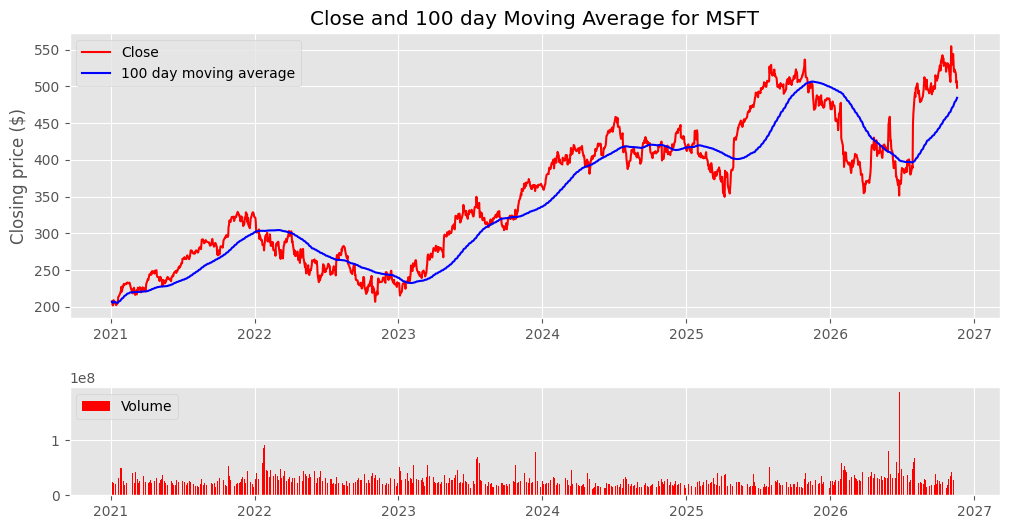

In [5]:
# Padmanaabh Kajaria  |  MGS 314 Project 4
import datetime as dt
import matplotlib.pyplot as plt
from matplotlib import style
import pandas as pd
import yfinance as yf

startDate = dt.datetime(2021, 1, 1)
endDate = dt.datetime(2026, 11, 20)
style.use('ggplot')

df = yf.download("MSFT", start=startDate, end=endDate)
df.columns = df.columns.droplevel(1)
df.to_csv('msft.csv')

pd.set_option("display.precision", 2)
df = pd.read_csv('msft.csv', parse_dates=True, index_col=0)
df['100ma'] = df['Close'].rolling(window=100, min_periods=0).mean()
df

plt.figure(figsize=(12, 6))
ax1 = plt.subplot2grid((8,1), (0,0), rowspan=5, colspan=1)
ax2 = plt.subplot2grid((8,1), (6,0), rowspan=3, colspan=1, sharex=ax1)
ax1.plot(df.index, df['Close'], 'r', label='Close')
ax1.plot(df.index, df['100ma'], 'b', label='100 day moving average')
ax1.set_ylabel('Closing price ($)')
ax1.set_title('Close and 100 day Moving Average for MSFT')
ax1.legend()
ax2.bar(df.index, df['Volume'], label='Volume', color='r')
ax2.legend()
plt.show()